# Preprocesado de la señal

> 🧭 **En 30 segundos**
> - **Para qué:** dejar la señal de todos los tramos **en el mismo formato**, sea cual sea el equipo con el que se grabó.
> - **Entra:** `tramos.csv` + los EDF → **Sale:** `senales/*.npy` (22 canales × muestras, 256 Hz, µV, float16) y `senales.csv` (dónde está cada tramo y su calidad)
> - **Idea clave:** la cadena es la misma que usará la demo en directo (filtro causal, funciones sin MNE), y aún no se descarta nada.

> 📍 **Dónde estamos: Fase 2 · notebook 2 de 4.** `01_seleccion_crisis` ya decidió **qué trozos de qué EDF** se usan (`tramos.csv`). Este notebook **lee esos trozos y deja la señal en un formato común**.

| Fase del TFM | | Estado |
|---|---|---|
| Fase 1 | Exploración de datos | ✅ terminada |
| **Fase 2** | **Preprocesado y ventanas** | 👉 **en curso** (la fase de este notebook) |
| Fase 3 | Modelo de predicción (preictal frente a interictal) | pendiente |
| Fase 4 | Clasificación de tipos de crisis | pendiente |
| Fase 5 | Explicabilidad (XAI) | pendiente |
| Fase 6 | Memoria | pendiente |
| Fase 7 | Revisión y defensa | pendiente |

## Qué hace este notebook

Cada EDF de TUSZ viene de un equipo distinto: con otra referencia (LE o AR), con o sin A1/A2 y a 250, 256, 400, 512 o 1000 Hz. Para que el modelo vea siempre lo mismo, cada tramo de `tramos.csv` pasa por la **misma cadena**:

1. **Montaje bipolar TCP de 22 canales**: así da igual la referencia original. Si al fichero le faltan A1/A2, sus 2 canales se dejan **a 0** y se marcan como no válidos: todas las señales tienen la misma forma (22 × muestras).
2. **Paso a µV**.
3. **Remuestreo a 256 Hz**.
4. **Filtro paso banda de 0,5–40 Hz y notch de 60 Hz**, como se decidió en el EDA.
5. **Guardado en float16**: un `.npy` por tramo, sin normalizar.

La **normalización no se aplica aquí**: la hace el cargador de la Fase 3 en cada ventana, para poder probar varias sin repetir el preprocesado (sección 8).

**Tarda**: del orden de **1–2 horas** (lee unos 5.000 EDF). Se puede **parar y reanudar**: al volver a ejecutarlo, se salta los tramos ya guardados. Para probar antes con pocos ficheros, pon `SOLO_PRUEBA = 20` en la sección 2.

**Requisito**: haber ejecutado `fase_02/01_seleccion_crisis.ipynb` (genera `tramos.csv`).

## Los notebooks de la Fase 2

| | Notebook | Qué hace | Entrada → salida | Estado |
|---|---|---|---|---|
| | `01_seleccion_crisis` | Elige qué señal se usa: tramos preictal, interictal e ictal, con su fichero, inicio y fin. | Inventario de la Fase 1 → `tramos.csv` | ✅ terminado |
| 👉 | `02_preprocesado` | **Deja la señal en un formato común**: montaje TCP de 22 canales, 256 Hz, filtrado, float16. Mide la calidad de cada tramo. | EDF + `tramos.csv` → `senales/*.npy` + `senales.csv` | **este notebook** |
| | `03_ventanas` | Corta la señal en **ventanas de 4 s**, decide a qué modelo pertenece cada una y marca las de mala calidad. | `senales.csv` → `ventanas.csv` | ✅ hecho |
| | `04_particiones_y_balanceo` | Mantiene el reparto por paciente y equilibra las clases solo en train (con un máximo de horas de interictal por paciente). | Ventanas → conjuntos listos para la Fase 3 | próximamente |

## 1. Importación de librerías

Además de `pandas`, `numpy` y `matplotlib`, aquí se lee señal: `mne` (lectura del EDF) y `scipy` (remuestreo y filtros). Las utilidades comunes vienen de `tfm_comun/`, cada una de su módulo. Las del preprocesado están todas en **`tfm_comun/senal/`** y son **funciones sueltas, sin MNE** (salvo la lectura del EDF), para poder **reutilizarlas tal cual en la demo** en tiempo real:

| Módulo | Qué hace | En la demo |
|---|---|---|
| `montaje.py` | `tcp_desde_referencial()`: 22 canales TCP, a 0 los que no se pueden construir | igual |
| `remuestreo.py` | `remuestrear()` a 256 Hz | igual (o el equipo ya graba a 256 Hz) |
| `filtrado.py` | `filtrar()`: paso banda + notch, **causal** | `FiltroContinuo`: el mismo filtro, a trozos |
| `preprocesado.py` | el **orden** de la cadena | `preprocesar_referencial()` |
| `normalizacion.py` | z-score o robusta, por ventana y canal | igual |
| `calidad.py` | amplitud máxima, canales planos | para avisar de electrodos sueltos |
| `senales.py` | guardar y cargar los `.npy` en float16 | — |

In [16]:
# Recarga automática: si cambia un módulo de tfm_comun, se vuelve a cargar solo (sin reiniciar el kernel)
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

# tfm_comun está en ALMA, por encima de la carpeta de la fase: lo añadimos al path de Python
sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'tfm_comun').is_dir())))
# Vuelve a leer tfm_comun del disco cada vez que se ejecuta esta celda (por si ha cambiado), sin reiniciar el kernel
for modulo in [m for m in list(sys.modules) if m == 'tfm_comun' or m.startswith('tfm_comun.')]:
    del sys.modules[modulo]

import json
import shutil
import time

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Patch
import mne
import scipy
from scipy.signal import welch, sosfreqz
from tqdm import tqdm
from IPython.display import display, Markdown

from tfm_comun.entorno.rutas import RUTA_OUTPUTS_FASE_02, RUTA_SENALES, indice_edf
from tfm_comun.dataset.particiones import SPLITS
from tfm_comun.visual.iconos import con_icono, tabla_con_iconos
from tfm_comun.visual.colores import COLORES_SPLIT, COLORES_PERIODO, COLORES_ETIQUETA, COLOR_DESTACADO
from tfm_comun.visual.numeros import numero_legible
from tfm_comun.visual.ejes import eje_log_legible
from tfm_comun.dataset.edf import leer_edf_tusz
from tfm_comun.senal.montaje import CANALES_TCP, CANALES_FIGURAS, senal_tcp
from tfm_comun.senal.remuestreo import FS_OBJETIVO
from tfm_comun.senal.filtrado import PASO_BANDA_HZ, NOTCH_HZ, ORDEN_PASO_BANDA, CALIDAD_NOTCH, disenar_filtro
from tfm_comun.senal.preprocesado import preprocesar_raw, VOLTIOS_A_MICROVOLTIOS
from tfm_comun.senal.normalizacion import NORMALIZACIONES
from tfm_comun.senal.calidad import indicadores_calidad, UMBRAL_PLANO_UV
from tfm_comun.senal.senales import (id_tramo, ruta_relativa, guardar_tramo, cargar_tramo, bytes_tramo,
                               TIPO_DATO, LIMITE_UV)
from tfm_comun.visual.tablas import con_separadores, mostrar_destacado
from tfm_comun.entorno.versiones import mostrar_versiones
from tfm_comun.visual.ficheros import mostrar_fichero

versiones_usadas = mostrar_versiones(np, pd, matplotlib, mne, scipy)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Python      3.14.0
numpy       2.5.4
pandas      3.0.6
matplotlib  3.11.2
mne         1.13.2
scipy       1.18.1


## Conceptos clave

- **Tramo**: trozo continuo de un EDF elegido en `01_seleccion_crisis`, de una de las tres **clases** (iconos de `tfm_comun/visual/iconos.py`): △ `interictal` (lejos de cualquier crisis), ◭ `preictal` (se acerca una crisis) o ▲ `ictal` (la crisis). Aquí se convierte en una matriz **22 canales × muestras**.
- **Montaje TCP**: cada canal es la resta de dos electrodos vecinos (`FP1-F7`, `F7-T3`...). Elimina la referencia, que es lo que más cambia entre equipos.
- **Remuestreo**: cambiar el número de muestras por segundo. Se hace **antes** de filtrar, para que el filtro sea siempre el mismo (diseñado a 256 Hz) en todos los ficheros y en la demo.
- **Filtro causal**: solo usa el pasado de la señal, como pasará en la demo (la señal llega en directo). Así el modelo se entrena con **exactamente** la misma señal que verá en la demo.
- **Margen de lectura**: se leen 10 s más a cada lado de los tramos, para que el filtro **arranque** antes del tramo y no al principio de él.
- **float16**: números de 2 bytes en vez de 4. La mitad de disco (unos 36 GB en vez de 72) con un error de centésimas a décimas de µV, muy por debajo del ruido del EEG (`tfm_comun/imagenes/senales_float16.png`).

El esquema de abajo resume la cadena (`tfm_comun/senal/preprocesado.py`).

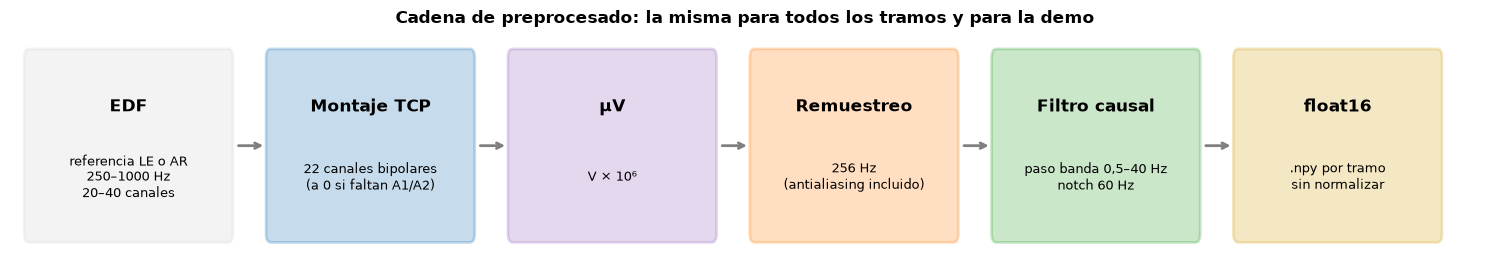

In [17]:
# Esquema de la cadena de preprocesado (tfm_comun/senal/preprocesado.py)
pasos = [
    ('EDF', 'referencia LE o AR\n250–1000 Hz\n20–40 canales', 'lightgray'),
    ('Montaje TCP', '22 canales bipolares\n(a 0 si faltan A1/A2)', 'tab:blue'),
    ('µV', 'V × 10⁶', 'tab:purple'),
    ('Remuestreo', f'{FS_OBJETIVO} Hz\n(antialiasing incluido)', 'tab:orange'),
    ('Filtro causal', f'paso banda {numero_legible(PASO_BANDA_HZ[0])}–{numero_legible(PASO_BANDA_HZ[1])} Hz\nnotch {NOTCH_HZ} Hz', 'tab:green'),
    ('float16', '.npy por tramo\nsin normalizar', COLOR_DESTACADO),
]
fig, ax = plt.subplots(figsize=(15, 2.8))
ancho, hueco = 2.1, 0.45
for i, (titulo, detalle, color) in enumerate(pasos):
    x = i * (ancho + hueco)
    ax.add_patch(FancyBboxPatch((x, 0), ancho, 1, boxstyle='round,pad=0.05', facecolor=color, alpha=0.25,
                                edgecolor=color, linewidth=2))
    ax.text(x + ancho / 2, 0.72, titulo, ha='center', va='center', fontsize=12, fontweight='bold')
    ax.text(x + ancho / 2, 0.32, detalle, ha='center', va='center', fontsize=9)
    if i < len(pasos) - 1:
        ax.annotate('', xy=(x + ancho + hueco - 0.05, 0.5), xytext=(x + ancho + 0.08, 0.5),
                    arrowprops=dict(arrowstyle='->', lw=2, color='gray'))
ax.set_xlim(-0.2, len(pasos) * (ancho + hueco))
ax.set_ylim(-0.15, 1.15)
ax.axis('off')
ax.set_title('Cadena de preprocesado: la misma para todos los tramos y para la demo', fontweight='bold')
fig.tight_layout()
plt.show()

## 2. Configuración

| Parámetro | Valor | Qué controla |
|---|---|---|
| `SOLO_PRUEBA` | `None` | Si es un número, solo procesa ese número de ficheros (para probar). `None` = todos |
| `SOBRESCRIBIR` | `False` | `True` vuelve a preprocesar todo, aunque ya esté guardado (p. ej. si cambia el filtro) |
| `MARGEN_LECTURA_S` | 10 | Segundos que se leen de más a cada lado de los tramos, para que el filtro arranque antes |
| `MARGEN_DISCO` | 1,1 | Hace falta un 10 % más de espacio libre que lo que se va a escribir |
| `FICHERO_EJEMPLO` | `aaaaacrb_s001_t001` | Fichero de las figuras: la 🟩 ausencia de ejemplo de la Fase 1 (250 Hz, referencia LE) |

La **frecuencia** (256 Hz), los **filtros** y el **formato** (float16) no se fijan aquí: vienen de `remuestreo.py`, `filtrado.py` y `senales.py`, para que la demo use los mismos.

La primera celda tiene la etiqueta `parameters`, por si se lanza con papermill.

In [18]:
SOLO_PRUEBA = 20        # p. ej. 20 para probar con 20 ficheros
SOBRESCRIBIR = True
MARGEN_LECTURA_S = 10
MARGEN_DISCO = 1.1
FICHERO_EJEMPLO = 'aaaaacrb_s001_t001'

> ⚠️ **Ahora mismo está en modo prueba**: `SOLO_PRUEBA = 20` y `SOBRESCRIBIR = True`. Para la ejecución completa, pon `SOLO_PRUEBA = None` y `SOBRESCRIBIR = False`. Con `SOBRESCRIBIR = True` se borra `progreso.csv` y **cada ejecución empieza de cero**, así que no se podría parar y reanudar.

In [19]:
# Rutas
RUTA_SELECCION = RUTA_OUTPUTS_FASE_02 / '01_seleccion'
RUTA_RESULTADOS = RUTA_OUTPUTS_FASE_02 / '02_preprocesado'
RUTA_FIGURAS = RUTA_RESULTADOS / 'figuras'
RUTA_FIGURAS.mkdir(parents=True, exist_ok=True)
RUTA_SENALES.mkdir(parents=True, exist_ok=True)
RUTA_PROGRESO = RUTA_RESULTADOS / 'progreso.csv'   # una fila por tramo ya guardado (para reanudar)
RUTA_ERRORES = RUTA_RESULTADOS / 'errores.csv'

# Carga de tramos.csv
assert (RUTA_SELECCION / 'tramos.csv').exists(), \
    f'No encuentro {RUTA_SELECCION / "tramos.csv"}. Ejecuta antes fase_02/01_seleccion_crisis.ipynb.'
tramos = pd.read_csv(RUTA_SELECCION / 'tramos.csv')
tramos['id_tramo'] = [id_tramo(f, c, i) for f, c, i in zip(tramos.file, tramos.clase, tramos.inicio_s)]
tramos['ruta'] = [ruta_relativa(s, c, i) for s, c, i in zip(tramos.split, tramos.clase, tramos.id_tramo)]
tramos['n_muestras_esperadas'] = (tramos.duracion_s * FS_OBJETIVO).round().astype(int)
assert tramos.id_tramo.is_unique, 'Hay dos tramos con el mismo identificador.'
assert FICHERO_EJEMPLO in set(tramos.file), f'{FICHERO_EJEMPLO} no tiene tramos en tramos.csv.'

# Dónde está cada EDF (se recorre el dataset una vez)
edf_de = indice_edf()
faltan = sorted(set(tramos.file) - set(edf_de))
assert not faltan, f'No encuentro {len(faltan)} EDF, por ejemplo {faltan[:3]}'
print(f'{numero_legible(len(tramos))} tramos de {numero_legible(tramos.file.nunique())} ficheros · '
      f'{numero_legible(tramos.duracion_s.sum() / 3600)} h de señal · todos los EDF localizados')

config = {
    'tramos': str(RUTA_SELECCION / 'tramos.csv'),
    'senales': str(RUTA_SENALES),
    'fs_hz': FS_OBJETIVO,
    'canales': CANALES_TCP,
    'paso_banda_hz': PASO_BANDA_HZ,
    'orden_paso_banda': ORDEN_PASO_BANDA,
    'notch_hz': NOTCH_HZ,
    'calidad_notch': CALIDAD_NOTCH,
    'filtro': 'Butterworth causal (sosfilt), con estado inicial',
    'orden_cadena': ['montaje TCP 22 canales', 'µV', f'remuestreo a {FS_OBJETIVO} Hz', 'paso banda', 'notch'],
    'tipo_dato': np.dtype(TIPO_DATO).name,
    'unidad': 'µV',
    'limite_uv': LIMITE_UV,
    'normalizada': False,
    'margen_lectura_s': MARGEN_LECTURA_S,
    'umbral_canal_plano_uv': UMBRAL_PLANO_UV,
    'solo_prueba': SOLO_PRUEBA,
    'fichero_ejemplo': FICHERO_EJEMPLO,
    'versiones': versiones_usadas,
    'fecha': time.strftime('%Y-%m-%d %H:%M'),
}
with open(RUTA_RESULTADOS / 'configuracion.json', 'w', encoding='utf-8') as f:
    json.dump(config, f, indent=4, ensure_ascii=False)
mostrar_fichero(RUTA_RESULTADOS / 'configuracion.json',
                'parámetros de la cadena de preprocesado (frecuencia, filtros, orden de los pasos, formato float16), las versiones y la fecha')

7.665 tramos de 5.134 ficheros · 896,5 h de señal · todos los EDF localizados


💾 **Guardado `configuracion.json`** · 1,5 KB · 20 claves  
*Qué guarda:* parámetros de la cadena de preprocesado (frecuencia, filtros, orden de los pasos, formato float16), las versiones y la fecha. *Abajo:* todas las claves (son pocas).

,valor
clave,
tramos,D:\Dani\TFM IA\03.Codigo\ALMA\outputs\fase_02\01_seleccion\tramos.csv
senales,D:\Dani\TFM IA\03.Codigo\ALMA\outputs\fase_02\02_preprocesado\senales
fs_hz,256
canales,"[""FP1-F7"", ""F7-T3"", ""T3-T5"", ""T5-O1"", ""FP2-F8"", ""F8-T4"", ""T4-T6"", ""T6-O2"", ""A1-T3"", ""T3-C3…"
paso_banda_hz,"[0.5, 40]"
orden_paso_banda,4
notch_hz,60
calidad_notch,30
filtro,"Butterworth causal (sosfilt), con estado inicial"


## 3. ¿Cabe en el disco?

Antes de escribir nada se calcula **lo que va a ocupar** cada tramo (22 canales × muestras × 2 bytes) y se compara con el **espacio libre** del disco donde está `senales/`. Si no cabe (con un 10 % de margen), el notebook **se para aquí**.

Solo cuenta lo **pendiente**: si se reanuda, lo ya guardado no se vuelve a sumar.

In [20]:
# Tramos ya guardados (de una ejecución anterior), salvo que se quiera sobrescribir
if RUTA_PROGRESO.exists() and not SOBRESCRIBIR:
    progreso = pd.read_csv(RUTA_PROGRESO).drop_duplicates('id_tramo', keep='last')
    progreso = progreso[[(RUTA_SENALES / r).exists() for r in progreso.ruta]]
else:
    progreso = pd.DataFrame()
    RUTA_PROGRESO.unlink(missing_ok=True)
hechos = set(progreso.id_tramo) if len(progreso) else set()
pendientes = tramos[~tramos.id_tramo.isin(hechos)]
ficheros_pendientes = list(pendientes.file.unique())
if SOLO_PRUEBA:
    ficheros_pendientes = ficheros_pendientes[:SOLO_PRUEBA]
    pendientes = pendientes[pendientes.file.isin(ficheros_pendientes)]

# Lo que va a ocupar, por clase y partición
ocupacion = tramos.assign(GB=[bytes_tramo(len(CANALES_TCP), n) / 1e9 for n in tramos.n_muestras_esperadas],
                          horas=tramos.duracion_s / 3600)
tabla_ocupacion = ocupacion.pivot_table(index='clase', columns='split', values='GB', aggfunc='sum') \
                           .reindex(columns=SPLITS).fillna(0).round(2)
tabla_ocupacion['total'] = tabla_ocupacion.sum(axis=1)
tabla_ocupacion.loc['total'] = tabla_ocupacion.sum()

necesario_gb = ocupacion[ocupacion.id_tramo.isin(pendientes.id_tramo)].GB.sum()
libre_gb = shutil.disk_usage(RUTA_SENALES).free / 1e9
display(Markdown(f'**GB en disco de toda la señal preprocesada** (float16), por clase y partición:'))
display(tabla_con_iconos(tabla_ocupacion))
display(Markdown(
    f'- Ya guardados: **{numero_legible(len(hechos))} tramos** · pendientes: **{numero_legible(len(pendientes))} tramos '
    f'de {numero_legible(len(ficheros_pendientes))} ficheros**\n'
    f'- Hace falta: **{numero_legible(round(necesario_gb, 1))} GB** (+ {round((MARGEN_DISCO - 1) * 100)} % de margen) · '
    f'libre en `{RUTA_SENALES.anchor}`: **{numero_legible(round(libre_gb, 1))} GB**'))
assert libre_gb >= necesario_gb * MARGEN_DISCO, \
    f'🔴 No cabe: hacen falta {necesario_gb * MARGEN_DISCO:.1f} GB y hay {libre_gb:.1f} GB libres. ' \
    'Libera espacio o cambia RUTA_SENALES (tfm_comun/entorno/rutas.py) a otro disco.'
print('✅ Hay espacio suficiente.')

**GB en disco de toda la señal preprocesada** (float16), por clase y partición:

split,🔵 train,🟡 dev,🟢 eval,total
clase,,,,
▲ ictal,1.35,0.30,0.27,1.92
△ interictal,15.60,13.70,2.86,32.16
◭ preictal,1.10,0.78,0.39,2.27
total,18.05,14.78,3.52,36.35


- Ya guardados: **0 tramos** · pendientes: **103 tramos de 20 ficheros**
- Hace falta: **0,2 GB** (+ 10 % de margen) · libre en `D:\`: **607,3 GB**

✅ Hay espacio suficiente.


👀 **Cómo leer la tabla.** GB que ocupará la señal preprocesada de **todos** los tramos (aunque estés en modo prueba), por clase y partición. Unos 36 GB en total, y casi todo es △ interictal (~32 GB): hay mucha más señal normal que de crisis. El mensaje final dice si cabe en el disco.

## 4. La cadena en un fichero de ejemplo

Antes de procesar los miles de ficheros, se comprueba en `FICHERO_EJEMPLO` que la cadena hace lo que debe. Se usa la **misma función** que en el bucle de la sección 5 (`preprocesar_raw`).

### 4.1. La señal antes y después

10 s alrededor del inicio de la crisis, en los canales de `CANALES_FIGURAS` (`tfm_comun/senal/montaje.py`: uno de cada cadena; para ver otros, se cambian allí). **Antes**: montaje TCP sin filtrar, a la frecuencia original. **Después**: la señal preprocesada. Debe verse lo mismo, pero sin la deriva lenta ni el ruido rápido.

aaaaacrb_s001_t001: 250 Hz, 20.7 min · antes (22, 310250) → después (22, 317696) · crisis 🟩 absz (🔹) en el segundo 97.4


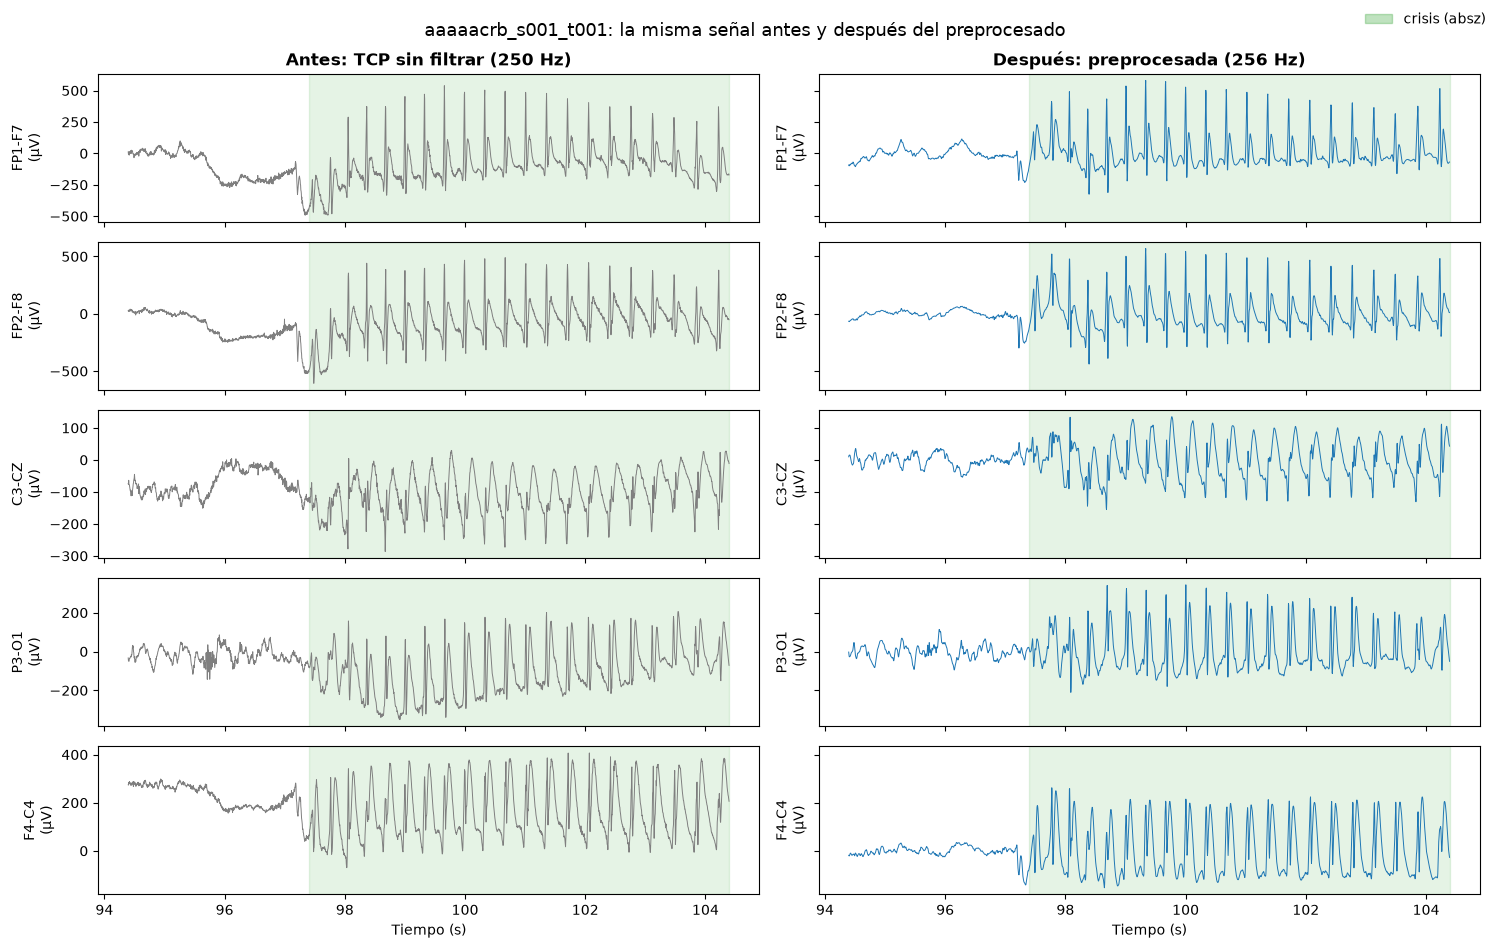

In [21]:
# Lectura y preprocesado del fichero completo (la misma función que en la sección 5)
raw_ejemplo = leer_edf_tusz(edf_de[FICHERO_EJEMPLO])
fs_original = raw_ejemplo.info['sfreq']
antes_uv, validos_ejemplo = senal_tcp(raw_ejemplo)
antes_uv = antes_uv * VOLTIOS_A_MICROVOLTIOS
despues_uv, _ = preprocesar_raw(raw_ejemplo)
crisis_ejemplo = tramos[(tramos.file == FICHERO_EJEMPLO) & (tramos.clase == 'ictal')].iloc[0]
print(f'{FICHERO_EJEMPLO}: {fs_original:g} Hz, {raw_ejemplo.times[-1] / 60:.1f} min · '
      f'antes {antes_uv.shape} → después {despues_uv.shape} · crisis {con_icono(crisis_ejemplo.tipo)} '
      f'en el segundo {crisis_ejemplo.inicio_s:.1f}')

inicio_fig, duracion_fig = crisis_ejemplo.inicio_s - 3, 10
fig, axes = plt.subplots(len(CANALES_FIGURAS), 2, figsize=(15, 1.9 * len(CANALES_FIGURAS)), sharex=True, sharey='row')
for columna, (senal, fs, titulo) in enumerate([(antes_uv, fs_original, f'Antes: TCP sin filtrar ({fs_original:g} Hz)'),
                                               (despues_uv, FS_OBJETIVO, f'Después: preprocesada ({FS_OBJETIVO} Hz)')]):
    a, b = int(inicio_fig * fs), int((inicio_fig + duracion_fig) * fs)
    t = np.arange(a, b) / fs
    for fila, canal in enumerate(CANALES_FIGURAS):
        ax = axes[fila, columna]
        ax.plot(t, senal[CANALES_TCP.index(canal), a:b], lw=0.7, color='tab:gray' if columna == 0 else 'tab:blue')
        ax.axvspan(crisis_ejemplo.inicio_s, min(crisis_ejemplo.fin_s, inicio_fig + duracion_fig),
                   color=COLORES_ETIQUETA[crisis_ejemplo.tipo], alpha=0.12)
        ax.set_ylabel(f'{canal}\n(µV)')
        if fila == 0:
            ax.set_title(titulo, fontweight='bold')
axes[-1, 0].set_xlabel('Tiempo (s)')
axes[-1, 1].set_xlabel('Tiempo (s)')
fig.legend(handles=[Patch(color=COLORES_ETIQUETA[crisis_ejemplo.tipo], alpha=0.3, label=f'crisis ({crisis_ejemplo.tipo})')],
           loc='upper right', frameon=False)
fig.suptitle(f'{FICHERO_EJEMPLO}: la misma señal antes y después del preprocesado', fontsize=13)
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / 'antes_despues_senal.png', dpi=150, bbox_inches='tight')
plt.show()

👀 **Qué mirar.** Cada fila es un canal; izquierda la señal original (gris), derecha la preprocesada (azul), con la misma escala vertical. La franja de color es la crisis. La forma de las ondas debe ser **la misma**; solo desaparecen la deriva lenta y la "pelusa" rápida.

### 4.2. El espectro antes y después, y la respuesta del filtro

**Izquierda**: potencia de cada frecuencia (media de los canales, todo el fichero). Después del filtro debe caer por debajo de 0,5 Hz y por encima de 40 Hz, y el pico de **60 Hz** (la red eléctrica) debe desaparecer.

**Derecha**: cuánto deja pasar el filtro de cada frecuencia (0 dB = todo; −3 dB = el 71 % de la amplitud, la mitad de la potencia; −20 dB = el 10 %; −40 dB = el 1 %). Es la figura que va a la memoria para justificar el filtro. Por qué se eligió este filtro (tipo, orden, notch, causal): `tfm_comun/senal/filtrado.py` y su figura `tfm_comun/imagenes/filtrado_explicacion.png`.

**El corte no es un muro, es una cuesta**: un corte de golpe metería "ecos" alrededor de las puntas. Por eso a 40 Hz todavía pasa el 71 %, a 50 Hz el 31 %, a 70 Hz el 4 % y a 100 Hz el 0,1 %. Lo empinada que es la cuesta la decide el **orden** del filtro (`ORDEN_PASO_BANDA = 4` en `filtrado.py`): más orden, más empinada, pero más ecos y más retraso.

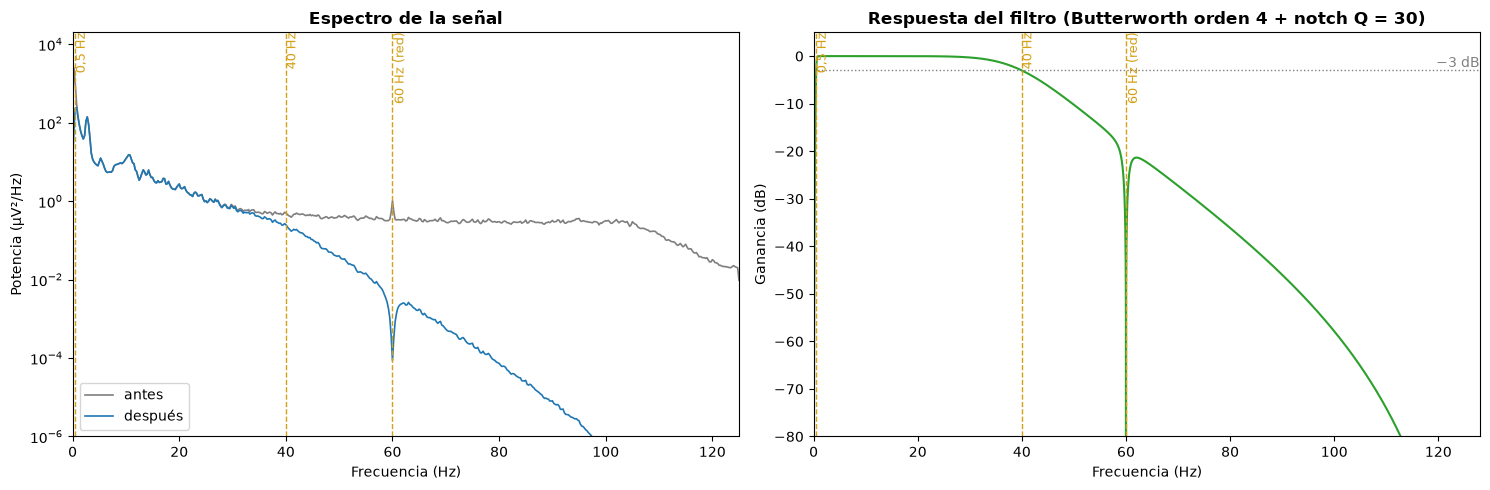

Hz,0.1,0.5,1.0,10.0,40.0,50.0,60.0
ganancia (dB),-58.5,-3.0,-0.0,-0.0,-3.0,-10.2,-311.3


In [22]:
fig, (ax_psd, ax_filtro) = plt.subplots(1, 2, figsize=(15, 5))

# Espectro (Welch, ventanas de 4 s)
for senal, fs, etiqueta, color in [(antes_uv, fs_original, 'antes', 'tab:gray'),
                                   (despues_uv, FS_OBJETIVO, 'después', 'tab:blue')]:
    f, p = welch(senal[validos_ejemplo], fs=fs, nperseg=int(4 * fs))
    ax_psd.semilogy(f, p.mean(axis=0), color=color, lw=1.2, label=etiqueta)
ax_psd.set_xlim(0, min(fs_original, 2 * FS_OBJETIVO) / 2)
ax_psd.set_ylim(bottom=1e-6)
ax_psd.set_xlabel('Frecuencia (Hz)')
ax_psd.set_ylabel('Potencia (µV²/Hz)')
ax_psd.set_title('Espectro de la señal', fontweight='bold')

# Respuesta del filtro completo (paso banda + notch) a 256 Hz
f, h = sosfreqz(disenar_filtro(FS_OBJETIVO), worN=8192, fs=FS_OBJETIVO)
ax_filtro.plot(f, 20 * np.log10(np.abs(h) + 1e-12), color='tab:green', lw=1.5)
ax_filtro.axhline(-3, color='gray', ls=':', lw=1)
ax_filtro.text(FS_OBJETIVO / 2, -3, ' −3 dB', va='bottom', ha='right', color='gray')
ax_filtro.set_ylim(-80, 5)
ax_filtro.set_xlim(0, FS_OBJETIVO / 2)
ax_filtro.set_xlabel('Frecuencia (Hz)')
ax_filtro.set_ylabel('Ganancia (dB)')
ax_filtro.set_title(f'Respuesta del filtro (Butterworth orden {ORDEN_PASO_BANDA} + notch Q = {CALIDAD_NOTCH})',
                    fontweight='bold')

for ax in (ax_psd, ax_filtro):
    for frecuencia, texto in [(PASO_BANDA_HZ[0], f'{numero_legible(PASO_BANDA_HZ[0])} Hz'), (PASO_BANDA_HZ[1], f'{numero_legible(PASO_BANDA_HZ[1])} Hz'),
                              (NOTCH_HZ, f'{NOTCH_HZ} Hz (red)')]:
        ax.axvline(frecuencia, color=COLOR_DESTACADO, ls='--', lw=1)
        ax.text(frecuencia, 1, f' {texto}', transform=ax.get_xaxis_transform(), va='top', fontsize=9,
                color=COLOR_DESTACADO, rotation=90)
ax_psd.legend(loc='lower left')
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / 'espectro_y_filtro.png', dpi=150, bbox_inches='tight')
plt.show()

ganancia = lambda hz: 20 * np.log10(np.abs(h[np.argmin(np.abs(f - hz))]))
display(pd.DataFrame({'ganancia (dB)': [ganancia(hz) for hz in [0.1, PASO_BANDA_HZ[0], 1, 10, PASO_BANDA_HZ[1], 50, NOTCH_HZ]]},
                     index=pd.Index([0.1, PASO_BANDA_HZ[0], 1, 10, PASO_BANDA_HZ[1], 50, NOTCH_HZ], name='Hz')).round(1).T)

👀 **La tabla de debajo** resume la figura de la derecha: ganancia del filtro en algunas frecuencias. 0 dB (1–10 Hz) = pasa todo; −3 dB = las frecuencias de corte (0,5 y 40 Hz); a 60 Hz la ganancia es enorme y negativa: el notch elimina la red eléctrica.

## 5. Preprocesado de todos los tramos

Para cada **fichero** (no para cada tramo, así cada EDF se lee **una sola vez**):

1. Se lee solo el trozo que va desde el primer tramo hasta el último, con `MARGEN_LECTURA_S` de más a cada lado.
2. Se preprocesa entero con `preprocesar_raw` (la misma función de la sección 4).
3. Se corta cada tramo y se guarda en `senales/<split>/<clase>/<id_tramo>.npy`, con sus **indicadores de calidad** (`calidad.py`).
4. Se apunta en `progreso.csv`. Si se para el notebook (o se va la luz), al volver a ejecutarlo **empieza donde lo dejó**.

Si un fichero da error, **no se para todo**: se apunta en `errores.csv` y se sigue con el siguiente.

In [23]:
errores = []
inicio_bucle = time.time()
for fichero in tqdm(ficheros_pendientes, desc='Ficheros', unit='EDF'):
    tramos_fichero = pendientes[pendientes.file == fichero]
    try:
        raw = leer_edf_tusz(edf_de[fichero], tramos_fichero.inicio_s.min() - MARGEN_LECTURA_S,
                            tramos_fichero.fin_s.max() + MARGEN_LECTURA_S)
        desfase_s = raw.first_samp / raw.info['sfreq']   # segundo del fichero en el que empieza lo leído
        senal, validos = preprocesar_raw(raw)
        filas = []
        for t in tramos_fichero.itertuples():
            primera = round((t.inicio_s - desfase_s) * FS_OBJETIVO)
            trozo = senal[:, primera:primera + t.n_muestras_esperadas]
            recortadas = guardar_tramo(RUTA_SENALES / t.ruta, trozo)
            filas.append({'id_tramo': t.id_tramo, 'ruta': t.ruta, 'n_muestras': trozo.shape[1],
                          'fs_original': raw.info['sfreq'], 'mascara_canales': ''.join('1' if v else '0' for v in validos),
                          **indicadores_calidad(trozo, validos), 'fraccion_recortada': recortadas})
        pd.DataFrame(filas).to_csv(RUTA_PROGRESO, mode='a', header=not RUTA_PROGRESO.exists(), index=False)
    except Exception as e:
        errores.append({'file': fichero, 'error': repr(e)})

pd.DataFrame(errores, columns=['file', 'error']).to_csv(RUTA_ERRORES, index=False)
mostrar_fichero(RUTA_ERRORES,
                'una fila por fichero EDF que dio error al preprocesarse (vacío si todo fue bien)')
print(f'{numero_legible(len(ficheros_pendientes))} ficheros en {(time.time() - inicio_bucle) / 60:.1f} min · '
      f'errores: {len(errores)}' + (' 🔴 (ver errores.csv)' if errores else ' ✅'))
if errores:
    display(pd.DataFrame(errores).head(10))

Ficheros: 100%|██████████| 20/20 [00:07<00:00,  2.63EDF/s]


💾 **Guardado `errores.csv`** · 73 B · 1 filas × 2 columnas  
*Qué guarda:* una fila por fichero EDF que dio error al preprocesarse (vacío si todo fue bien). *Abajo:* las 1 primeras filas.

,file,error
0,aaaaabyy_s001_t001,"PermissionError(13, 'Acceso denegado')"


20 ficheros en 0.1 min · errores: 1 🔴 (ver errores.csv)


,file,error
0,aaaaabyy_s001_t001,"PermissionError(13, 'Acceso denegado')"


👀 **Qué mirar.** La barra de progreso avanza por ficheros EDF. Al final, `errores.csv` tiene que salir **vacío** y el mensaje terminar en ✅. Si hay errores, el resto se ha procesado igual; basta con revisar esos ficheros y volver a ejecutar.

### 5.1. Qué se ha guardado

El bucle escribe **dos cosas**. Se vuelven a leer **del disco** para ver exactamente lo que hay:

1. **`progreso.csv`**: una fila por tramo ya guardado, con dónde está su `.npy` y su calidad. Sirve para **reanudar** si se para, y en la sección 6 se une con `tramos.csv` para formar `senales.csv`.
2. **Un `.npy`** (el primero de `progreso.csv`): la señal de un tramo. Es una **matriz**: **una fila por canal TCP** (22) y **una columna por muestra** (256 por segundo). Se muestran las 5 primeras muestras, es decir, los primeros 20 ms. Cada número es el voltaje de ese canal en ese instante, en **µV**.

In [24]:
# 1. progreso.csv
progreso_guardado = pd.read_csv(RUTA_PROGRESO)
display(Markdown(f'**`progreso.csv`**: {numero_legible(len(progreso_guardado))} filas (una por tramo guardado) × '
                 f'{progreso_guardado.shape[1]} columnas. Las 5 primeras:'))
display(progreso_guardado.head(5))

# 2. Un .npy: matriz canales × muestras
ejemplo_npy = progreso_guardado.iloc[0]
matriz = cargar_tramo(RUTA_SENALES / ejemplo_npy.ruta, en_memoria=True)
tabla_npy = pd.DataFrame(matriz[:, :5].astype(np.float32), index=pd.Index(CANALES_TCP, name='canal TCP'),
                         columns=[f'muestra {i} ({i * 1000 / FS_OBJETIVO:.0f} ms)' for i in range(5)])
display(Markdown(f'**`{ejemplo_npy.ruta}`**: matriz de **{matriz.shape[0]} canales × {numero_legible(matriz.shape[1])} muestras** '
                 f'({matriz.shape[1] / FS_OBJETIVO:.0f} s a {FS_OBJETIVO} Hz), tipo `{matriz.dtype}`, en µV. '
                 f'Las 5 primeras muestras de cada canal (los canales a 0 son los que no se pudieron construir):'))
display(tabla_npy.style.format('{:.1f}'))

**`progreso.csv`**: 101 filas (una por tramo guardado) × 10 columnas. Las 5 primeras:

,id_tramo,ruta,n_muestras,fs_original,mascara_canales,amplitud_max_uv,desviacion_mediana_uv,canales_planos,canales_validos,fraccion_recortada
0,aaaaaacz_s006_t000_preictal_000409636,train/preictal/aaaaaacz_s006_t000_preictal_000...,171622,256.0,1111111101111011111111,141.974792,6.678638,0,20,0.0
1,aaaaaacz_s006_t000_ictal_000086031,train/ictal/aaaaaacz_s006_t000_ictal_000086031...,6044,256.0,1111111101111011111111,109.489906,7.702436,0,20,0.0
2,aaaaaacz_s006_t000_ictal_001140039,train/ictal/aaaaaacz_s006_t000_ictal_001140039...,11528,256.0,1111111101111011111111,132.202103,19.125809,0,20,0.0
3,aaaaaajy_s003_t005_preictal_000000000,dev/preictal/aaaaaajy_s003_t005_preictal_00000...,38131,400.0,1111111111111111111111,787.797546,14.966726,0,22,0.0
4,aaaaaajy_s003_t005_ictal_000208951,dev/ictal/aaaaaajy_s003_t005_ictal_000208951.npy,25585,400.0,1111111111111111111111,1780.457397,15.633480,0,22,0.0


**`train/preictal/aaaaaacz_s006_t000_preictal_000409636.npy`**: matriz de **22 canales × 171.622 muestras** (670 s a 256 Hz), tipo `float16`, en µV. Las 5 primeras muestras de cada canal (los canales a 0 son los que no se pudieron construir):

,muestra 0 (0 ms),muestra 1 (4 ms),muestra 2 (8 ms),muestra 3 (12 ms),muestra 4 (16 ms)
canal TCP,,,,,
FP1-F7,0.1,1.2,2.5,3.1,2.4
F7-T3,6.2,6.4,7.1,7.1,5.9
T3-T5,3.7,3.7,2.4,0.8,0.2
T5-O1,1.1,0.3,-0.3,-0.7,-0.8
FP2-F8,-0.2,0.5,1.1,1.2,0.9
F8-T4,5.9,6.2,6.2,6.4,7.0
T4-T6,0.4,-0.3,-0.6,-1.0,-1.9
T6-O2,4.3,3.4,3.2,3.0,2.8
A1-T3,0.0,0.0,0.0,0.0,0.0


## 6. Tabla única de señales → `senales.csv` y comprobaciones

`senales.csv` = `tramos.csv` + dónde está la señal de cada tramo + sus indicadores de calidad. Es la **entrada de `03_ventanas`**.

Al final de la celda se muestran 5 filas de la tabla tal como se guarda. Antes de guardarla se comprueba que:

1. **Todos los tramos** tienen su `.npy` (si no, falta terminar el bucle o hay errores).
2. Cada tramo tiene **las muestras que debe** (duración × 256, ±2 muestras de redondeo).
3. Una muestra de `.npy` se lee bien: **forma 22 × muestras, float16, sin NaN ni infinitos**.
4. Los ficheros sin A1/A2 (`03_tcp_ar_a`) tienen **20 canales válidos** y el resto **22**.

In [25]:
progreso = pd.read_csv(RUTA_PROGRESO).drop_duplicates('id_tramo', keep='last')
senales = tramos.merge(progreso.drop(columns='ruta'), on='id_tramo', how='left')
completo = SOLO_PRUEBA is None

# 1. Todos los tramos guardados
sin_senal = senales.n_muestras.isna()
print(f'1. Tramos sin señal guardada (debe ser 0{"" if completo else ", salvo en modo prueba"}): {sin_senal.sum()}')
guardados = senales[~sin_senal].copy()

# 2. Número de muestras
diferencia = (guardados.n_muestras - guardados.n_muestras_esperadas).abs()
print(f'2. Tramos con un número de muestras distinto del esperado (debe ser 0): {(diferencia > 2).sum()}')

# 3. Lectura de una muestra de ficheros
muestra = guardados.sample(min(200, len(guardados)), random_state=0)
malos = 0
for r in muestra.itertuples():
    x = cargar_tramo(RUTA_SENALES / r.ruta, en_memoria=True)
    malos += not (x.shape == (len(CANALES_TCP), r.n_muestras) and x.dtype == TIPO_DATO and np.isfinite(x).all())
print(f'3. De {len(muestra)} .npy leídos al azar, con forma, tipo o valores incorrectos (debe ser 0): {malos}')

# 4. Canales válidos según el montaje original
esperados = np.where(guardados.montage == '03_tcp_ar_a', 20, 22)
canales_mal = (guardados.canales_validos != esperados).sum()
print(f'4. Tramos con un número de canales válidos inesperado (debe ser 0): {canales_mal}')

assert (diferencia > 2).sum() == 0 and malos == 0 and canales_mal == 0 and (sin_senal.sum() == 0 or not completo), \
    '🔴 Alguna comprobación ha fallado: revisa el bucle y errores.csv.'

senales = senales.drop(columns='n_muestras_esperadas')

# Así queda la tabla que se guarda en senales.csv (las columnas nuevas, al final)
display(Markdown(f'**Tabla que se guarda en `senales.csv`**: {numero_legible(len(senales))} filas (una por tramo) × '
                 f'{senales.shape[1]} columnas: las de `tramos.csv` más dónde está la señal y su calidad. '
                 'Las 5 primeras con señal:'))
display(senales[senales.n_muestras.notna()].head(5))
senales.to_csv(RUTA_RESULTADOS / 'senales.csv', index=False)
disco_gb = sum((RUTA_SENALES / r).stat().st_size for r in guardados.ruta) / 1e9
print(f'✅ senales.csv guardado: {numero_legible(len(guardados))} tramos con señal · '
      f'{numero_legible(round(disco_gb, 1))} GB en {RUTA_SENALES}')

1. Tramos sin señal guardada (debe ser 0, salvo en modo prueba): 7564
2. Tramos con un número de muestras distinto del esperado (debe ser 0): 0
3. De 101 .npy leídos al azar, con forma, tipo o valores incorrectos (debe ser 0): 0
4. Tramos con un número de canales válidos inesperado (debe ser 0): 0


**Tabla que se guarda en `senales.csv`**: 7.665 filas (una por tramo) × 38 columnas: las de `tramos.csv` más dónde está la señal y su calidad. Las 5 primeras con señal:

,clase,split,patient,session,file,montage,fs,tipo,grupo,crisis_id,...,id_tramo,ruta,n_muestras,fs_original,mascara_canales,amplitud_max_uv,desviacion_mediana_uv,canales_planos,canales_validos,fraccion_recortada
0,preictal,train,aaaaaacz,s006,aaaaaacz_s006_t000,03_tcp_ar_a,256.0,gnsz,generalizada,aaaaaacz_s006_t000_c01,...,aaaaaacz_s006_t000_preictal_000409636,train/preictal/aaaaaacz_s006_t000_preictal_000...,171622.0,256.0,1111111101111011111111,141.974792,6.678638,0.0,20.0,0.0
1,preictal,dev,aaaaaajy,s003,aaaaaajy_s003_t005,01_tcp_ar,400.0,fnsz,focal,aaaaaajy_s003_t005_c00,...,aaaaaajy_s003_t005_preictal_000000000,dev/preictal/aaaaaajy_s003_t005_preictal_00000...,38131.0,400.0,1111111111111111111111,787.797546,14.966726,0.0,22.0,0.0
2,preictal,eval,aaaaaarq,s014,aaaaaarq_s014_t009,01_tcp_ar,256.0,gnsz,generalizada,aaaaaarq_s014_t009_c00,...,aaaaaarq_s014_t009_preictal_000000000,eval/preictal/aaaaaarq_s014_t009_preictal_0000...,149248.0,256.0,1111111111111111111111,5757.367676,10.567616,0.0,22.0,0.0
3,preictal,eval,aaaaaarq,s017,aaaaaarq_s017_t001,01_tcp_ar,256.0,gnsz,generalizada,aaaaaarq_s017_t001_c00,...,aaaaaarq_s017_t001_preictal_000000000,eval/preictal/aaaaaarq_s017_t001_preictal_0000...,30469.0,256.0,1111111111111111111111,109.716408,9.840700,0.0,22.0,0.0
4,preictal,eval,aaaaaarq,s017,aaaaaarq_s017_t005,01_tcp_ar,256.0,gnsz,generalizada,aaaaaarq_s017_t005_c00,...,aaaaaarq_s017_t005_preictal_000000000,eval/preictal/aaaaaarq_s017_t005_preictal_0000...,112166.0,256.0,1111111111111111111111,163.597870,7.170163,0.0,22.0,0.0


✅ senales.csv guardado: 101 tramos con señal · 0,2 GB en D:\Dani\TFM IA\03.Codigo\ALMA\outputs\fase_02\02_preprocesado\senales


👀 **Cómo leerlo.** En modo prueba, la comprobación 1 **no** da 0 (faltan los tramos que no se han procesado): es normal. Las comprobaciones 2, 3 y 4 sí tienen que dar 0 siempre.

### 6.1. Qué hay en `senales.csv`

<div style="background:#fff6d8; color:#1a1a1a; border:2px solid #d4a017; border-radius:8px; padding:10px 14px">
<span style="color:#1a1a1a">🏆 <b style="color:#1a1a1a">El resultado de este notebook.</b> <b style="color:#1a1a1a">senales.csv</b> dice, para cada tramo, <b style="color:#1a1a1a">dónde está su señal preprocesada</b> y <b style="color:#1a1a1a">qué calidad tiene</b>. Junto con la carpeta <b style="color:#1a1a1a">senales/</b>, es la entrada de <b style="color:#1a1a1a">03_ventanas</b>.</span>
</div>

Se vuelve a leer el **fichero recién guardado**. Las columnas de `tramos.csv` ya se explicaron en `01_seleccion_crisis` (sección 8.1); aquí solo las **nuevas**.

In [26]:
senales_csv = pd.read_csv(RUTA_RESULTADOS / 'senales.csv')
DESCRIPCION_NUEVAS = {
    'id_tramo': 'Identificador del tramo: fichero_clase_inicio en ms (no cambia si se repite 01_seleccion)',
    'ruta': 'Dónde está su .npy, dentro de senales/ (<split>/<clase>/<id_tramo>.npy)',
    'n_muestras': f'Muestras del tramo a {FS_OBJETIVO} Hz (la matriz es 22 × n_muestras)',
    'fs_original': 'Frecuencia original del EDF (Hz), antes de remuestrear',
    'mascara_canales': 'Un 1 o un 0 por canal TCP, en el orden de CANALES_TCP: 0 = no se pudo construir (está a 0)',
    'amplitud_max_uv': 'Mayor valor absoluto del tramo (µV): muy alto = artefacto',
    'desviacion_mediana_uv': 'Desviación típica mediana de los canales (µV): nivel típico de la señal',
    'canales_planos': f'Canales válidos con desviación < {UMBRAL_PLANO_UV} µV (electrodo suelto o apagado)',
    'canales_validos': 'Canales que se pudieron construir (22, o 20 sin A1/A2)',
    'fraccion_recortada': f'Fracción de muestras que pasaban de ±{numero_legible(LIMITE_UV)} µV y se recortaron',
}
columnas_nuevas = pd.DataFrame({
    'tipo de dato': senales_csv[list(DESCRIPCION_NUEVAS)].dtypes.astype(str),
    'ejemplo': [senales_csv[c].dropna().iloc[0] if senales_csv[c].notna().any() else '—' for c in DESCRIPCION_NUEVAS],
    'qué es': list(DESCRIPCION_NUEVAS.values()),
})
columnas_nuevas.index.name = 'columna'
mostrar_destacado(
    'senales.csv: dónde está y cómo es la señal de cada tramo',
    f'<b>{numero_legible(len(senales_csv))} filas × {senales_csv.shape[1]} columnas</b> · una fila = un tramo · '
    f'señal en <b>senales/</b> ({numero_legible(round(disco_gb, 1))} GB, float16, µV, sin normalizar)',
    '<b>Columnas nuevas</b> (el resto, como en tramos.csv)', columnas_nuevas,
    '<b>3 filas de ejemplo de cada clase</b>',
    tabla_con_iconos(senales_csv.groupby('clase', group_keys=False).head(3)
                     .set_index('clase')[['split', 'tipo', 'file', 'duracion_s', *DESCRIPCION_NUEVAS]].fillna('—'),
                     columnas=['split', 'tipo']))

,tipo de dato,ejemplo,qué es
columna,,,
id_tramo,str,aaaaaacz_s006_t000_preictal_000409636,Identificador del tramo: fichero_clase_inicio en ms (no cambia si se repite 01_seleccion)
ruta,str,train/preictal/aaaaaacz_s006_t000_preictal_000409636.npy,"Dónde está su .npy, dentro de senales/ (<split>/<clase>/<id_tramo>.npy)"
n_muestras,float64,171622.0,Muestras del tramo a 256 Hz (la matriz es 22 × n_muestras)
fs_original,float64,256.0,"Frecuencia original del EDF (Hz), antes de remuestrear"
mascara_canales,object,1111111101111011111111,"Un 1 o un 0 por canal TCP, en el orden de CANALES_TCP: 0 = no se pudo construir (está a 0)"
amplitud_max_uv,float64,141.974792,Mayor valor absoluto del tramo (µV): muy alto = artefacto
desviacion_mediana_uv,float64,6.678638,Desviación típica mediana de los canales (µV): nivel típico de la señal
canales_planos,float64,0.0,Canales válidos con desviación < 0.5 µV (electrodo suelto o apagado)
canales_validos,float64,20.0,"Canales que se pudieron construir (22, o 20 sin A1/A2)"


## 7. Calidad de la señal

Aquí **no se descarta nada**: solo se mira cómo es la señal, para decidir con datos en `03_ventanas` qué se tira. Primero una figura (con su explicación debajo) y después dos tablas.

> ⚠️ En modo prueba (`SOLO_PRUEBA`) hay muy pocos tramos y la figura no es representativa: hay que mirarla con el preprocesado completo.

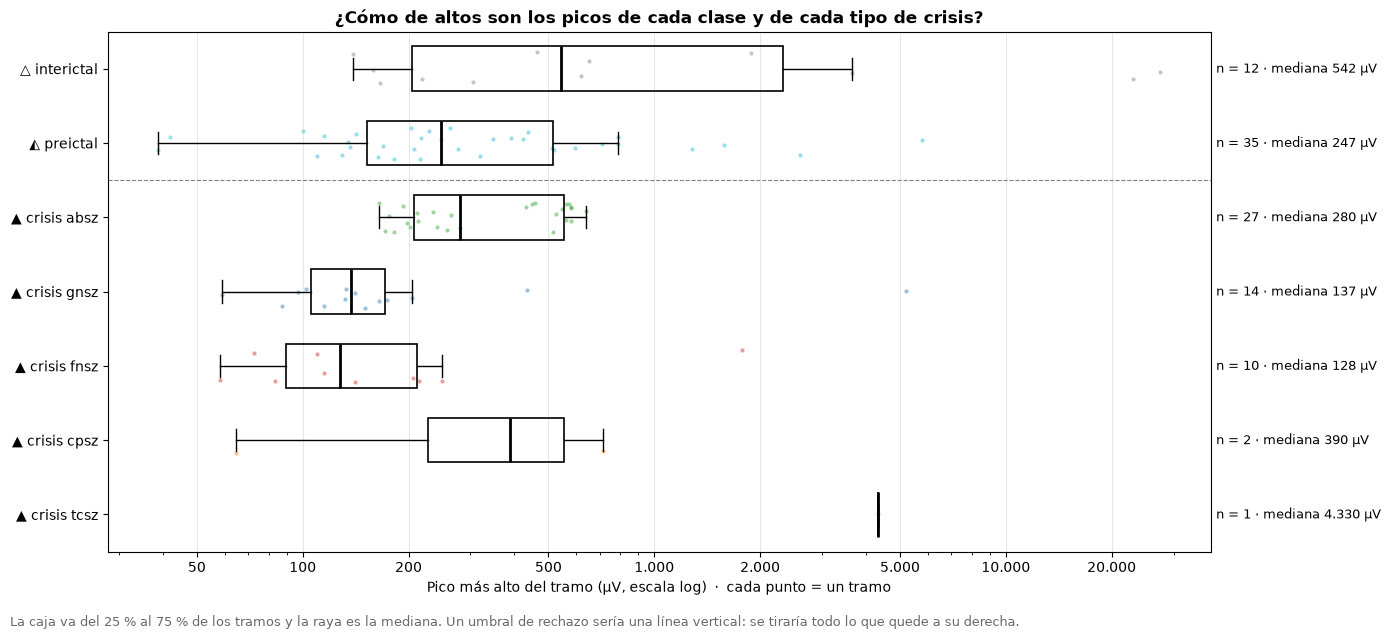

In [27]:
guardados = senales_csv[senales_csv.n_muestras.notna()]
ictales = guardados[guardados.clase == 'ictal']

# Una fila por grupo: primero lo que se quiere limpiar (△ ◭), después las crisis por tipo (▲)
filas_figura = [(f'{con_icono(clase)}', guardados[guardados.clase == clase].amplitud_max_uv, COLORES_PERIODO[clase])
                for clase in ['interictal', 'preictal']]
filas_figura += [(f'▲ crisis {tipo}', g.amplitud_max_uv, COLORES_ETIQUETA.get(tipo, 'black'))
                 for tipo, g in sorted(ictales.groupby('tipo'), key=lambda par: -len(par[1]))]

MAX_PUNTOS = 1500                      # por fila: con más, los puntos se tapan y la figura tarda
rng = np.random.default_rng(0)
fig, ax = plt.subplots(figsize=(14, 0.65 * len(filas_figura) + 1.8))
for y, (nombre, amplitudes, color) in enumerate(filas_figura):
    puntos = amplitudes.sample(min(MAX_PUNTOS, len(amplitudes)), random_state=0)
    ax.scatter(puntos, y + rng.uniform(-0.22, 0.22, len(puntos)), s=9, color=color, alpha=0.45, linewidths=0)
    ax.boxplot(amplitudes, positions=[y], orientation='horizontal', widths=0.6, showfliers=False, patch_artist=True,
               boxprops=dict(facecolor='none', edgecolor='black', lw=1.2),
               medianprops=dict(color='black', lw=2), whiskerprops=dict(color='black'), capprops=dict(color='black'))
    ax.text(1.005, y, f'n = {numero_legible(len(amplitudes))} · mediana {numero_legible(round(amplitudes.median()))} µV',
            transform=ax.get_yaxis_transform(), va='center', fontsize=9)
ax.axhline(1.5, color='gray', lw=0.8, ls='--')
ax.set_yticks(range(len(filas_figura)), [nombre for nombre, _, _ in filas_figura])
ax.invert_yaxis()
ax.set_xscale('log')
eje_log_legible(ax, 'x')
ax.set_xlabel('Pico más alto del tramo (µV, escala log)  ·  cada punto = un tramo')
ax.grid(axis='x', alpha=0.3)
ax.set_title('¿Cómo de altos son los picos de cada clase y de cada tipo de crisis?', fontweight='bold')
fig.text(0.01, 0.005, 'La caja va del 25 % al 75 % de los tramos y la raya es la mediana. Un umbral de rechazo sería una '
         'línea vertical: se tiraría todo lo que quede a su derecha.', fontsize=9, color='dimgray')
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(RUTA_FIGURAS / 'calidad_senal.png', dpi=150, bbox_inches='tight')
plt.show()

### 7.1. Qué hace la figura y qué pretende representar

**Qué hace.** De cada tramo guardado toma un solo número: su **pico más alto**, es decir, el mayor valor absoluto en µV de sus 22 canales, ya preprocesados (columna `amplitud_max_uv` de `senales.csv`). Después agrupa los tramos en filas y los dibuja:

- **Filas**: arriba las dos clases que se usarán para predecir (△ `interictal` y ◭ `preictal`); debajo de la línea discontinua, las crisis (▲ `ictal`) separadas por tipo, de la que más crisis tiene a la que menos.
- **Puntos**: cada punto es **un tramo**. Cuanto más a la derecha, más alto es su pico. El eje es **logarítmico** (100, 200, 500, 1.000...) para que quepan a la vez tramos de 50 µV y de 5.000 µV. Los puntos se separan un poco en vertical solo para que no se tapen.
- **Caja**: va del 25 % al 75 % de los tramos de esa fila (la mitad central); la **raya gruesa** es la mediana y los **bigotes** llegan hasta los tramos normales más alejados.
- **A la derecha**: cuántos tramos tiene la fila (n) y su mediana.

**Qué pretende representar.** Responde a la pregunta: **¿qué pasaría si se tiraran los tramos con picos demasiado altos?**

Un pico enorme casi nunca es actividad del cerebro: suele ser un **artefacto** (el paciente se mueve, mastica, se suelta un electrodo). Quitarlos limpia los datos, pero hay un riesgo: **algunas crisis también tienen picos muy altos**. Las ausencias tienen puntas-onda grandes y las tónico-clónicas, mucha actividad muscular.

**Un umbral de rechazo es una línea vertical imaginaria** sobre la figura: se tiraría todo lo que quede a su derecha. Así se ve de un vistazo:

- **Arriba** (△ ◭): cuántos tramos con artefactos se quitarían. Es lo que se **quiere**.
- **Abajo** (▲): qué crisis se perderían. Es lo que **no** se quiere. Si un tipo tiene la caja muy a la derecha, un umbral bajo se lo comería entero.

**Qué buscar.** Un buen umbral deja **a su izquierda casi todos los puntos de las crisis** y corta solo la cola de puntos sueltos de △ ◭. Si algún tipo de crisis (por ejemplo, 🟪 `tcsz` (🔷)) está mucho más a la derecha que el resto, habrá que tratarlo aparte o no aplicar el rechazo a las crisis. El número exacto se decide en `03_ventanas` con la tabla de abajo (p99 de cada tipo).

In [28]:
# Amplitud de las crisis por tipo: el umbral tendrá que quedar por encima (03_ventanas)
amplitud_crisis = ictales.groupby('tipo').amplitud_max_uv.describe(percentiles=[0.5, 0.95, 0.99])[
    ['count', '50%', '95%', '99%', 'max']].rename(columns={'count': 'crisis', '50%': 'mediana (µV)', '95%': 'p95 (µV)',
                                                           '99%': 'p99 (µV)', 'max': 'máximo (µV)'})
amplitud_crisis = amplitud_crisis.sort_values('crisis', ascending=False)
display(Markdown('**▲ Lo alto que llegan las crisis de cada tipo.** En `03_ventanas` el umbral de rechazo tendrá que '
                 'quedar por encima del p99 de cada tipo (o no aplicarse a las crisis):'))
display(con_separadores(tabla_con_iconos(amplitud_crisis), decimales=0))

def resumen_calidad(g):
    return pd.Series({
        'tramos': len(g), 'horas': g.duracion_s.sum() / 3600,
        'pico mediano (µV)': g.amplitud_max_uv.median(),
        'pico p99 (µV)': g.amplitud_max_uv.quantile(0.99),
        '% con canal plano': (g.canales_planos > 0).mean() * 100,
        '% con 20 canales': (g.canales_validos == 20).mean() * 100,
        '% con recortes': (g.fraccion_recortada > 0).mean() * 100,
    })
tabla_calidad = guardados.groupby(['split', 'clase']).apply(resumen_calidad, include_groups=False) \
                         .reindex(SPLITS, level=0)
display(Markdown('**Resto de indicadores de calidad, por partición y clase:**'))
display(con_separadores(tabla_con_iconos(tabla_calidad)))

**▲ Lo alto que llegan las crisis de cada tipo.** En `03_ventanas` el umbral de rechazo tendrá que quedar por encima del p99 de cada tipo (o no aplicarse a las crisis):

,crisis,mediana (µV),p95 (µV),p99 (µV),máximo (µV)
tipo,,,,,
🟩 absz (🔹),27,280,579,623,638
🟦 gnsz (🔷),14,137,2.097,4.568,5.186
🟥 fnsz (♦️),10,128,1.091,1.643,1.780
🟧 cpsz (♦️),2,390,683,709,715
🟪 tcsz (🔷),1,4.330,4.330,4.330,4.330


**Resto de indicadores de calidad, por partición y clase:**

👀 **Cómo leer las tablas.**

- **Crisis por tipo**: lo alto que llegan los picos de cada tipo (mediana, p95, p99 y máximo). Sirve para que el umbral de rechazo de `03_ventanas` no se coma crisis.
- **Indicadores por partición y clase**: `% con canal plano` alto = electrodos sueltos; `% con 20 canales` = ficheros sin A1/A2 (`03_tcp_ar_a`); `% con recortes` = tramos con muestras saturadas.

## 8. Vista previa: normalización (se aplicará al cargar las ventanas, en la Fase 3)

La señal se ha guardado **sin normalizar** (en µV). Se normalizará **cada ventana y cada canal por separado** con `tfm_comun/senal/normalizacion.py`, para que el modelo no dependa de la amplitud de cada paciente o equipo. En la demo bastará con la ventana que acaba de llegar.

Hay dos opciones; se compararán en la Fase 3:

- **z-score**: resta la media y divide por la desviación típica.
- **robusta**: mediana y rango intercuartílico. Un pico enorme (artefacto) no aplasta el resto de la ventana.

Abajo, una ventana de 4 s del inicio de la crisis de ejemplo, leída del `.npy` guardado (si ya existe).

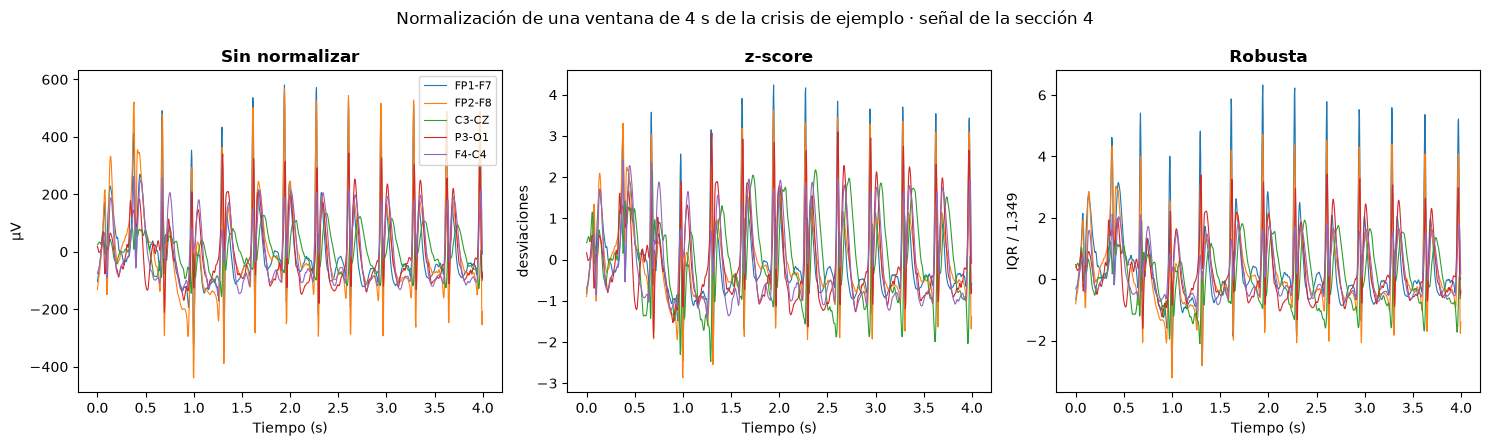

In [29]:
ictal_ejemplo = senales_csv[(senales_csv.file == FICHERO_EJEMPLO) & (senales_csv.clase == 'ictal') & senales_csv.n_muestras.notna()]
if len(ictal_ejemplo):
    ventana = cargar_tramo(RUTA_SENALES / ictal_ejemplo.iloc[0].ruta)[:, :4 * FS_OBJETIVO].astype(np.float32)
    origen_ventana = f'.npy guardado ({ictal_ejemplo.iloc[0].id_tramo})'
else:   # modo prueba sin el fichero de ejemplo: se usa la señal de la sección 4
    a = int(crisis_ejemplo.inicio_s * FS_OBJETIVO)
    ventana = despues_uv[:, a:a + 4 * FS_OBJETIVO]
    origen_ventana = 'señal de la sección 4'
t = np.arange(ventana.shape[1]) / FS_OBJETIVO
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True)
for ax, (titulo, x, unidad) in zip(axes, [('Sin normalizar', ventana, 'µV'),
                                          ('z-score', NORMALIZACIONES['zscore'](ventana), 'desviaciones'),
                                          ('Robusta', NORMALIZACIONES['robusta'](ventana), 'IQR / 1,349')]):
    for k, canal in enumerate(CANALES_FIGURAS):
        ax.plot(t, x[CANALES_TCP.index(canal)], lw=0.8, label=canal)
    ax.set_title(titulo, fontweight='bold')
    ax.set_xlabel('Tiempo (s)')
    ax.set_ylabel(unidad)
axes[0].legend(fontsize=8, loc='upper right')
fig.suptitle(f'Normalización de una ventana de 4 s de la crisis de ejemplo · {origen_ventana}', fontsize=12)
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / 'normalizacion_ejemplo.png', dpi=150, bbox_inches='tight')
plt.show()

👀 **Cómo leer la figura.** El mismo trozo de 4 s tres veces. A la izquierda, en µV; en el centro y a la derecha, normalizado: cada canal queda centrado en 0 y con una escala parecida. **La forma no cambia, solo la escala**: el modelo verá el ritmo y la forma, no lo grande que es la señal de cada paciente.

## 9. Resumen → `summary.txt`

Reúne los datos y las tablas principales del notebook, como en `01_seleccion_crisis`.

In [30]:
datos = [
    f'Preprocesado: {config["fecha"]}' + (f' · MODO PRUEBA ({SOLO_PRUEBA} ficheros)' if SOLO_PRUEBA else ''),
    f'Cadena: montaje TCP de {len(CANALES_TCP)} canales → µV → {FS_OBJETIVO} Hz → paso banda '
    f'{numero_legible(PASO_BANDA_HZ[0])}–{numero_legible(PASO_BANDA_HZ[1])} Hz (Butterworth orden {ORDEN_PASO_BANDA}, causal) → notch {NOTCH_HZ} Hz',
    f'Formato: .npy por tramo, {np.dtype(TIPO_DATO).name}, µV, sin normalizar · {numero_legible(round(disco_gb, 1))} GB',
    f'Tramos con señal: {numero_legible(len(guardados))} de {numero_legible(len(senales_csv))} · errores: {len(errores)} ficheros',
]
tablas_resumen = {
    'GB por clase y partición': tabla_con_iconos(tabla_ocupacion),
    'Calidad de la señal por partición y clase': tabla_con_iconos(tabla_calidad.round(1)),
    'Frecuencia original de los tramos': tabla_con_iconos(guardados.groupby(['fs_original', 'split']).size()
                                                         .unstack().reindex(columns=SPLITS).fillna(0).astype(int)),
}
texto = ('=== Preprocesado de la señal (Fase 2 · 02) ===\n' + '\n'.join(datos) + '\n\n'
         + '\n\n'.join(f'--- {titulo} ---\n{tabla.to_string()}' for titulo, tabla in tablas_resumen.items()) + '\n')
(RUTA_RESULTADOS / 'summary.txt').write_text(texto, encoding='utf-8')
mostrar_fichero(RUTA_RESULTADOS / 'summary.txt',
                'el resumen del preprocesado en texto, para consultarlo sin abrir el notebook')

display(Markdown('\n'.join(f'- {d}' for d in datos)))
for titulo, tabla in tablas_resumen.items():
    display(Markdown(f'#### {titulo}'))
    display(con_separadores(tabla))
print(f'Resumen guardado en {RUTA_RESULTADOS / "summary.txt"}')

💾 **Guardado `summary.txt`** · 2,4 KB · 33 líneas  
*Qué guarda:* el resumen del preprocesado en texto, para consultarlo sin abrir el notebook. *Abajo:* las 5 primeras líneas con texto.

,texto
línea,
1,=== Preprocesado de la señal (Fase 2 · 02) ===
2,Preprocesado: 2026-10-29 16:24 · MODO PRUEBA (20 ficheros)
3,"Cadena: montaje TCP de 22 canales → µV → 256 Hz → paso banda 0,5–40 Hz (Butterworth orden 4, causal) → notch 60 Hz"
4,"Formato: .npy por tramo, float16, µV, sin normalizar · 0,2 GB"
5,Tramos con señal: 101 de 7.665 · errores: 1 ficheros


- Preprocesado: 2026-10-29 16:24 · MODO PRUEBA (20 ficheros)
- Cadena: montaje TCP de 22 canales → µV → 256 Hz → paso banda 0,5–40 Hz (Butterworth orden 4, causal) → notch 60 Hz
- Formato: .npy por tramo, float16, µV, sin normalizar · 0,2 GB
- Tramos con señal: 101 de 7.665 · errores: 1 ficheros

#### GB por clase y partición

split,🔵 train,🟡 dev,🟢 eval,total
clase,,,,
▲ ictal,"1,4","0,3","0,3","1,9"
△ interictal,"15,6","13,7","2,9","32,2"
◭ preictal,"1,1","0,8","0,4","2,3"
total,"18,1","14,8","3,5","36,4"


#### Calidad de la señal por partición y clase

#### Frecuencia original de los tramos

split,🔵 train,🟡 dev,🟢 eval
fs_original,,,
250.0,59,19,0
256.0,3,0,13
400.0,2,5,0


Resumen guardado en D:\Dani\TFM IA\03.Codigo\ALMA\outputs\fase_02\02_preprocesado\summary.txt


## 10. Conclusiones

**1. Todas las señales tienen ya la misma forma**
- 22 canales TCP a 256 Hz, en µV, sea cual sea el equipo, la referencia o la frecuencia original. Los ficheros sin A1/A2 llevan esos 2 canales a 0, marcados en `mascara_canales`.

**2. El preprocesado es el mismo que tendrá la demo**
- Funciones de `tfm_comun` sin MNE (salvo leer el EDF) y un **filtro causal**: el modelo se entrena con la misma señal que verá en directo. `FiltroContinuo` filtra a trozos y da exactamente lo mismo que filtrar de golpe.

**3. float16 no pierde nada que importe**
- La mitad de disco que float32, con un error de centésimas a décimas de µV (`tfm_comun/imagenes/senales_float16.png`).

**4. La calidad se mide, pero aún no se descarta nada**
- `senales.csv` lleva la amplitud máxima, los canales planos y los recortes de cada tramo. El umbral de rechazo se decidirá **con datos** en `03_ventanas`: por encima del p99 de la amplitud de las crisis de cada tipo (tabla de la sección 7), tratando aparte 🟪 `tcsz` (🔷) si hace falta, o aplicándolo solo a △ interictal y ◭ preictal.

> ✏️ Las cifras de esta ejecución (GB, tramos con canales planos, amplitud de las crisis por tipo...) están en las secciones 6 y 7 y en `summary.txt`.

## 11. Archivos generados y siguiente paso

En `outputs/fase_02/02_preprocesado/`:

- `configuracion.json`: parámetros de la cadena (frecuencia, filtros, formato), versiones y fecha.
- `senales/<split>/<clase>/<id_tramo>.npy`: **la señal preprocesada**, una matriz 22 × muestras por tramo (float16, µV). ⚠️ Ocupa decenas de GB: **no subir a GitHub** (añadir `outputs/**/senales/` al `.gitignore`).
- `senales.csv`: **una fila por tramo** con dónde está su señal y su calidad. Es la entrada de `03_ventanas`.
- `progreso.csv`: tramos ya guardados (para reanudar). Se puede borrar al terminar.
- `errores.csv`: ficheros que dieron error (vacío si todo fue bien).
- `summary.txt`: tablas resumen (con iconos).
- `figuras/`: `antes_despues_senal.png`, `espectro_y_filtro.png`, `calidad_senal.png`, `normalizacion_ejemplo.png`.

**Siguiente paso**: `03_ventanas.ipynb`, que corta cada tramo en ventanas de 4 s, decide a qué modelo pertenece cada una y marca las de mala calidad.